# Week 3 Task: Exploratory Data Analysis (EDA)

**Agribusiness Data Analysis Internship**  
**Dataset:** FAOSTAT agricultural producer-price data

## Objective
Explore agricultural producer-price data using descriptive statistics, data-quality checks, distributions, time-series plots, commodity comparisons, outlier detection, and correlation analysis.

> Important: Keep measurement types separate. Producer prices in LCU, SLC, and USD per tonne are not directly comparable with a producer price index. The source dataset is annual, so it cannot support monthly or seasonal analysis by itself.

This notebook saves every chart as a PNG file and includes the charts, summary tables, detailed correlation results, and report outline in a ZIP archive at the end.


In [1]:
# STEP 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import shutil

from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Configure output folders early so every chart can be saved as it is created.
output_dir = "/content/Week3_EDA_Outputs"
chart_dir = os.path.join(output_dir, "charts")
os.makedirs(chart_dir, exist_ok=True)

_chart_counter = 0

def save_and_show():
    """Save the current Matplotlib figure as a PNG, then display it."""
    global _chart_counter
    _chart_counter += 1

    fig = plt.gcf()
    title = ""
    if fig.axes:
        title = fig.axes[0].get_title()

    safe_title = re.sub(r"[^A-Za-z0-9_-]+", "_", title).strip("_")
    if not safe_title:
        safe_title = "chart"

    filename = f"{_chart_counter:03d}_{safe_title[:90]}.png"
    fig.savefig(
        os.path.join(chart_dir, filename),
        dpi=200,
        bbox_inches="tight",
        facecolor="white"
    )
    print(f"Chart saved: {filename}")
    plt.show()

In [2]:
# STEP 2: Load the dataset

file_path = "/content/FAOSTAT_data_en_10-14-2026.csv"

if not os.path.exists(file_path):
    from google.colab import files
    uploaded = files.upload()
    file_path = next(iter(uploaded.keys()))

data = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Original dataset shape:", data.shape)
display(data.head())

Dataset loaded successfully.
Original dataset shape: (5035, 16)


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Months Code,Months,Unit,Value,Flag,Flag Description
0,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,LCU,29485.00,A,Official value
1,PP,Producer Prices,356,India,5531,Producer Price (SLC/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,SLC,29485.00,A,Official value
2,PP,Producer Prices,356,India,5532,Producer Price (USD/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,USD,624.90,A,Official value
3,PP,Producer Prices,356,India,5539,Producer Price Index (2014-2016 = 100),01654,"Anise, badian, coriander, cumin, caraway, fenn...",1991,1991,7021,Annual value,NaN,19.06,E,Estimated value
4,PP,Producer Prices,356,India,5539,Producer Price Index (2014-2016 = 100),01654,"Anise, badian, coriander, cumin, caraway, fenn...",1992,1992,7021,Annual value,NaN,17.96,E,Estimated value


In [3]:
# STEP 3: Standardize column names and prepare an analysis copy

def standardize_column(column):
    column = column.strip().lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)
    return column.strip("_")

data.columns = [standardize_column(col) for col in data.columns]
eda_data = data.copy()

for col in eda_data.select_dtypes(include=["object"]).columns:
    eda_data[col] = eda_data[col].str.strip()

for col in ["year", "year_code", "value"]:
    if col in eda_data.columns:
        eda_data[col] = pd.to_numeric(eda_data[col], errors="coerce")

required_columns = ["area", "element", "item", "year", "value"]
missing_columns = [col for col in required_columns if col not in eda_data.columns]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}. "
        "Check the source CSV headers."
    )

print("Standardized columns:")
print(eda_data.columns.tolist())

Standardized columns:
['domain_code', 'domain', 'area_code_m49', 'area', 'element_code', 'element', 'item_code_cpc', 'item', 'year_code', 'year', 'months_code', 'months', 'unit', 'value', 'flag', 'flag_description']


In [4]:
# STEP 4: Dataset overview

print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)

print("Rows:", eda_data.shape[0])
print("Columns:", eda_data.shape[1])
print("Geographic areas:", eda_data["area"].nunique())
print("Agricultural commodities:", eda_data["item"].nunique())
print("Measurement types:", eda_data["element"].nunique())
print("Year range:", eda_data["year"].min(), "to", eda_data["year"].max())

eda_data.info()
display(eda_data.head())

1. DATASET OVERVIEW
Rows: 5035
Columns: 16
Geographic areas: 1
Agricultural commodities: 104
Measurement types: 4
Year range: 1991 to 2025
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5035 entries, 0 to 5034
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   domain_code       5035 non-null   object 
 1   domain            5035 non-null   object 
 2   area_code_m49     5035 non-null   int64  
 3   area              5035 non-null   object 
 4   element_code      5035 non-null   int64  
 5   element           5035 non-null   object 
 6   item_code_cpc     5035 non-null   object 
 7   item              5035 non-null   object 
 8   year_code         5035 non-null   int64  
 9   year              5035 non-null   int64  
 10  months_code       5035 non-null   int64  
 11  months            5035 non-null   object 
 12  unit              1395 non-null   object 
 13  value             5035 non-null   float64
 1

,domain_code,domain,area_code_m49,area,element_code,element,item_code_cpc,item,year_code,year,months_code,months,unit,value,flag,flag_description
0,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,LCU,29485.00,A,Official value
1,PP,Producer Prices,356,India,5531,Producer Price (SLC/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,SLC,29485.00,A,Official value
2,PP,Producer Prices,356,India,5532,Producer Price (USD/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,USD,624.90,A,Official value
3,PP,Producer Prices,356,India,5539,Producer Price Index (2014-2016 = 100),01654,"Anise, badian, coriander, cumin, caraway, fenn...",1991,1991,7021,Annual value,NaN,19.06,E,Estimated value
4,PP,Producer Prices,356,India,5539,Producer Price Index (2014-2016 = 100),01654,"Anise, badian, coriander, cumin, caraway, fenn...",1992,1992,7021,Annual value,NaN,17.96,E,Estimated value


2. DATA QUALITY ANALYSIS


,Missing_Count,Missing_Percentage
unit,3640,72.29
domain_code,0,0.00
area_code_m49,0,0.00
domain,0,0.00
element_code,0,0.00
element,0,0.00
item_code_cpc,0,0.00
area,0,0.00
item,0,0.00
year_code,0,0.00


Exact duplicate rows: 0
Chart saved: 001_Missing_Values_by_Column.png


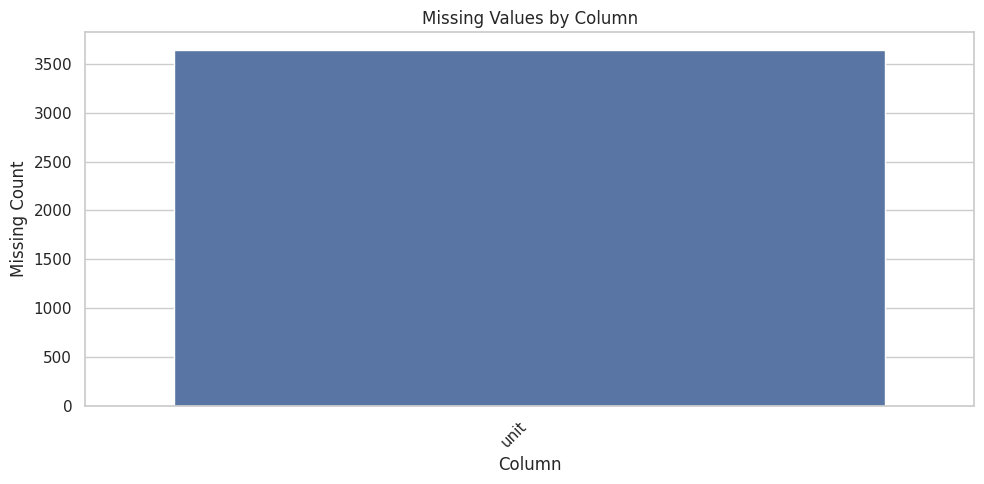

In [5]:
# STEP 5: Missing values and duplicate analysis

print("=" * 60)
print("2. DATA QUALITY ANALYSIS")
print("=" * 60)

missing_summary = pd.DataFrame({
    "Missing_Count": eda_data.isna().sum(),
    "Missing_Percentage": (eda_data.isna().mean() * 100).round(2)
})

display(missing_summary.sort_values("Missing_Percentage", ascending=False))
print("Exact duplicate rows:", eda_data.duplicated().sum())

missing_plot = missing_summary[missing_summary["Missing_Count"] > 0]

if not missing_plot.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing_plot.index, y=missing_plot["Missing_Count"])
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    save_and_show()
else:
    print("No missing values found.")

In [6]:
# STEP 6: Descriptive statistics by measurement type and unit

print("=" * 60)
print("3. DESCRIPTIVE STATISTICS")
print("=" * 60)

display(eda_data["value"].describe())

if "unit" in eda_data.columns:
    descriptive_stats = eda_data.groupby(
        ["element", "unit"], dropna=False
    )["value"].agg(
        Records="count",
        Mean="mean",
        Median="median",
        Standard_Deviation="std",
        Minimum="min",
        Maximum="max"
    ).reset_index()
else:
    descriptive_stats = eda_data.groupby(
        ["element"], dropna=False
    )["value"].agg(
        Records="count",
        Mean="mean",
        Median="median",
        Standard_Deviation="std",
        Minimum="min",
        Maximum="max"
    ).reset_index()

display(descriptive_stats.round(2))

3. DESCRIPTIVE STATISTICS


,value
count,5035.000000
mean,2997.266334
std,9835.320700
min,3.350000
25%,41.730000
50%,94.650000
75%,178.350000
max,158080.000000


,element,unit,Records,Mean,Median,Standard_Deviation,Minimum,Maximum
0,Producer Price (LCU/tonne),LCU,465,15736.97,11310.00,18029.44,373.00,158080.00
1,Producer Price (SLC/tonne),SLC,465,15736.97,11310.00,18029.44,373.00,158080.00
2,Producer Price (USD/tonne),USD,465,414.56,323.30,488.96,12.80,3910.60
3,Producer Price Index (2014-2016 = 100),NaN,3640,72.27,60.15,41.50,3.35,215.29


Chart saved: 002_Distribution_of_Values_Producer_Price_LCU_tonne.png


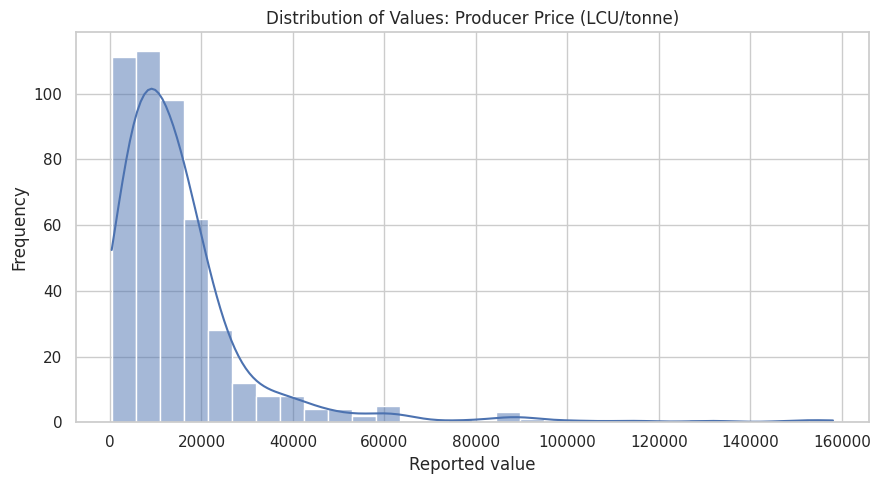

Chart saved: 003_Distribution_of_Values_Producer_Price_SLC_tonne.png


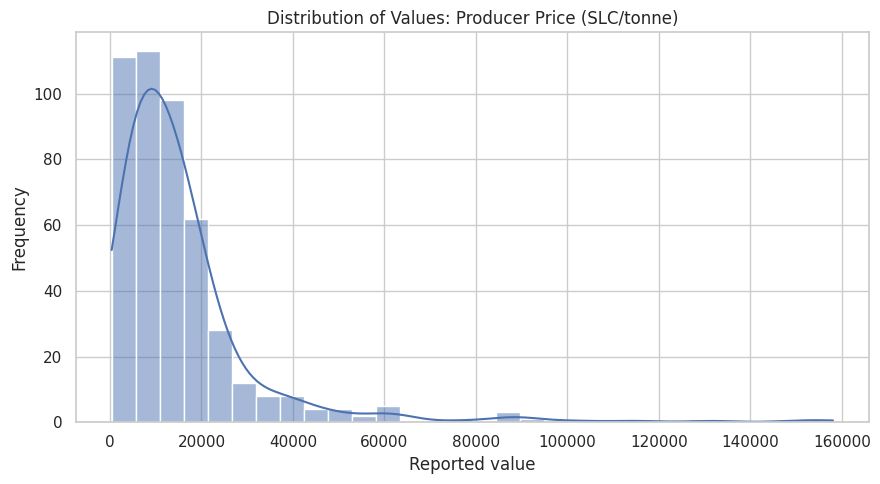

Chart saved: 004_Distribution_of_Values_Producer_Price_USD_tonne.png


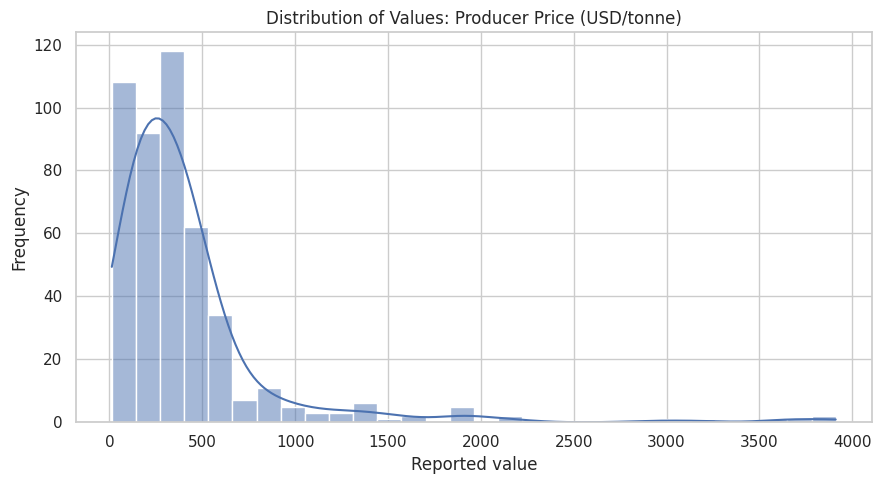

Chart saved: 005_Distribution_of_Values_Producer_Price_Index_2014-2016_100.png


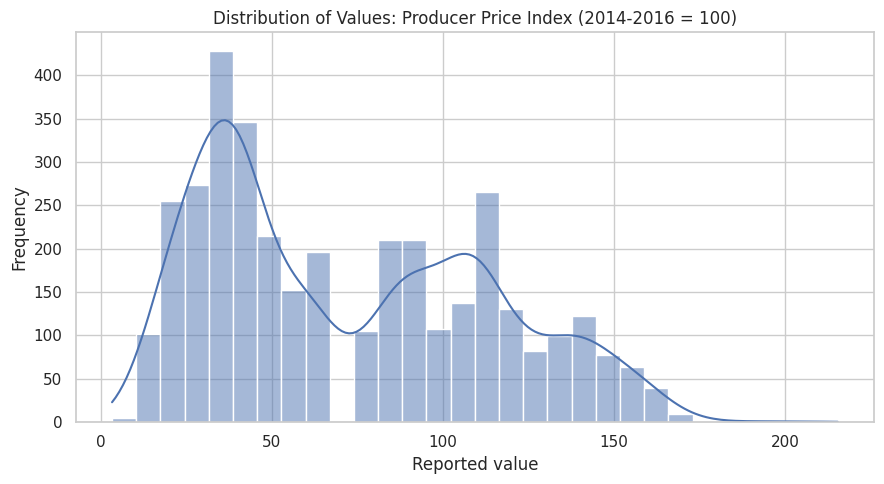

In [7]:
# STEP 7: Distribution analysis
# Separate plots by measurement type; do not combine unlike units.

for element in eda_data["element"].dropna().unique():
    values = eda_data.loc[
        eda_data["element"] == element, "value"
    ].dropna()

    if values.empty:
        continue

    plt.figure(figsize=(9, 5))
    sns.histplot(values, bins=30, kde=True)
    plt.title(f"Distribution of Values: {element}")
    plt.xlabel("Reported value")
    plt.ylabel("Frequency")
    plt.tight_layout()
    save_and_show()

In [8]:
# STEP 8: Filter to India when available

if eda_data["area"].astype(str).str.lower().eq("india").any():
    analysis_data = eda_data[
        eda_data["area"].astype(str).str.lower() == "india"
    ].copy()
else:
    analysis_data = eda_data.copy()
    print("India was not found; using all available areas.")

print("Rows used for trend and commodity analysis:", len(analysis_data))

Rows used for trend and commodity analysis: 5035


Chart saved: 006_Annual_Trends_by_Commodity_Producer_Price_LCU_tonne.png


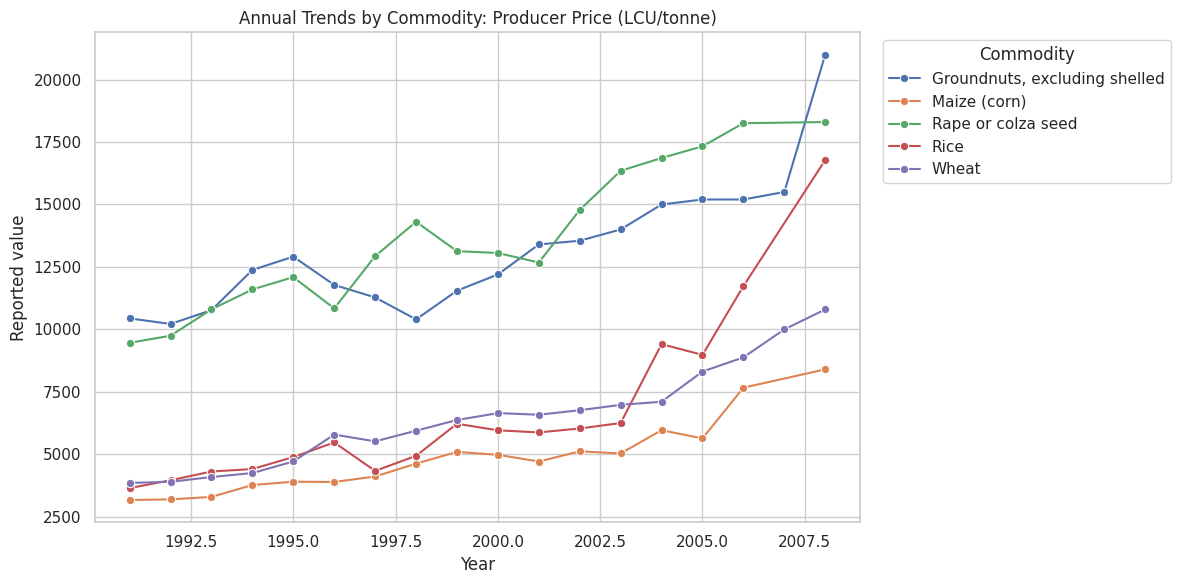


Measurement type: Producer Price (LCU/tonne)


,item,year,value,observations
0,"Groundnuts, excluding shelled",1991,10439.0,1
1,"Groundnuts, excluding shelled",1992,10219.0,1
2,"Groundnuts, excluding shelled",1993,10770.0,1
3,"Groundnuts, excluding shelled",1994,12380.0,1
4,"Groundnuts, excluding shelled",1995,12911.0,1
5,"Groundnuts, excluding shelled",1996,11780.0,1
6,"Groundnuts, excluding shelled",1997,11280.0,1
7,"Groundnuts, excluding shelled",1998,10400.0,1
8,"Groundnuts, excluding shelled",1999,11550.0,1
9,"Groundnuts, excluding shelled",2000,12200.0,1


Chart saved: 007_Annual_Trends_by_Commodity_Producer_Price_SLC_tonne.png


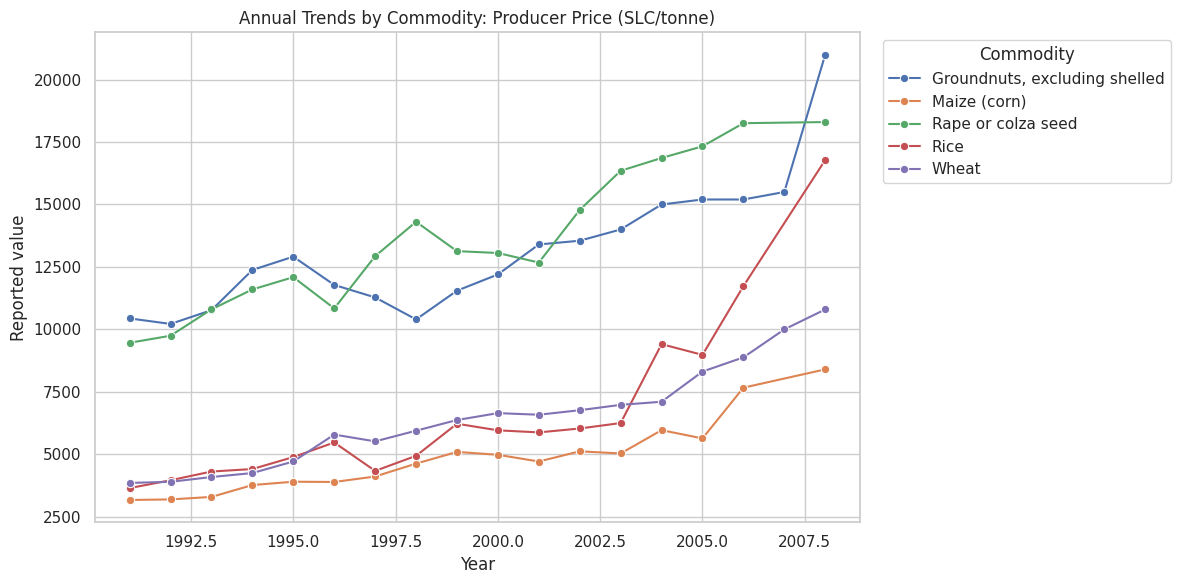


Measurement type: Producer Price (SLC/tonne)


,item,year,value,observations
0,"Groundnuts, excluding shelled",1991,10439.0,1
1,"Groundnuts, excluding shelled",1992,10219.0,1
2,"Groundnuts, excluding shelled",1993,10770.0,1
3,"Groundnuts, excluding shelled",1994,12380.0,1
4,"Groundnuts, excluding shelled",1995,12911.0,1
5,"Groundnuts, excluding shelled",1996,11780.0,1
6,"Groundnuts, excluding shelled",1997,11280.0,1
7,"Groundnuts, excluding shelled",1998,10400.0,1
8,"Groundnuts, excluding shelled",1999,11550.0,1
9,"Groundnuts, excluding shelled",2000,12200.0,1


Chart saved: 008_Annual_Trends_by_Commodity_Producer_Price_USD_tonne.png


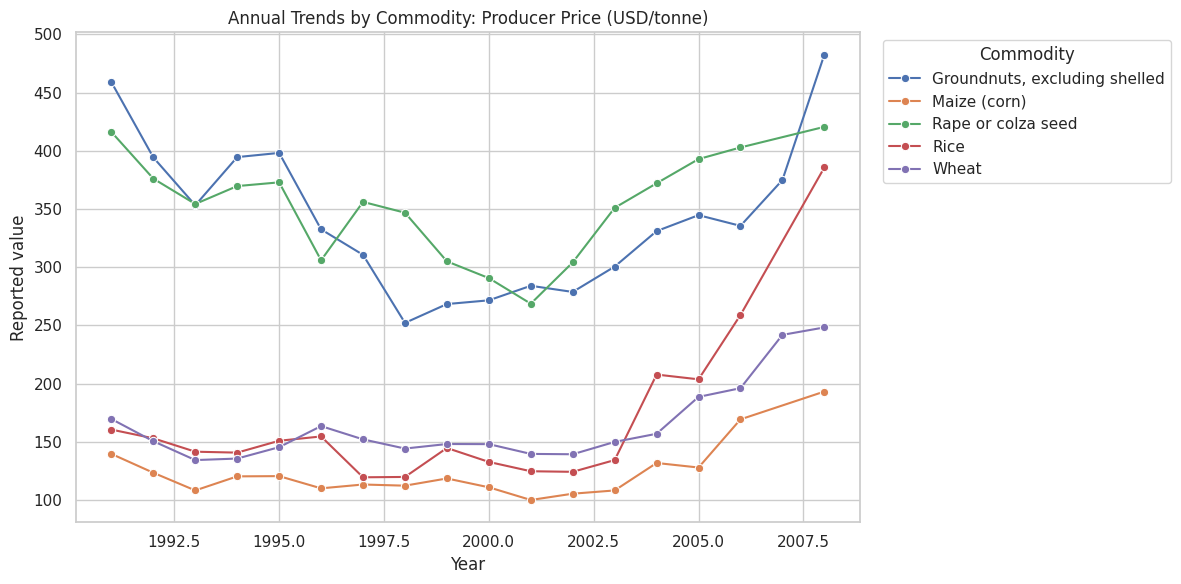


Measurement type: Producer Price (USD/tonne)


,item,year,value,observations
0,"Groundnuts, excluding shelled",1991,459.0,1
1,"Groundnuts, excluding shelled",1992,394.3,1
2,"Groundnuts, excluding shelled",1993,353.2,1
3,"Groundnuts, excluding shelled",1994,394.6,1
4,"Groundnuts, excluding shelled",1995,398.2,1
5,"Groundnuts, excluding shelled",1996,332.5,1
6,"Groundnuts, excluding shelled",1997,310.6,1
7,"Groundnuts, excluding shelled",1998,252.1,1
8,"Groundnuts, excluding shelled",1999,268.3,1
9,"Groundnuts, excluding shelled",2000,271.5,1


Chart saved: 009_Annual_Trends_by_Commodity_Producer_Price_Index_2014-2016_100.png


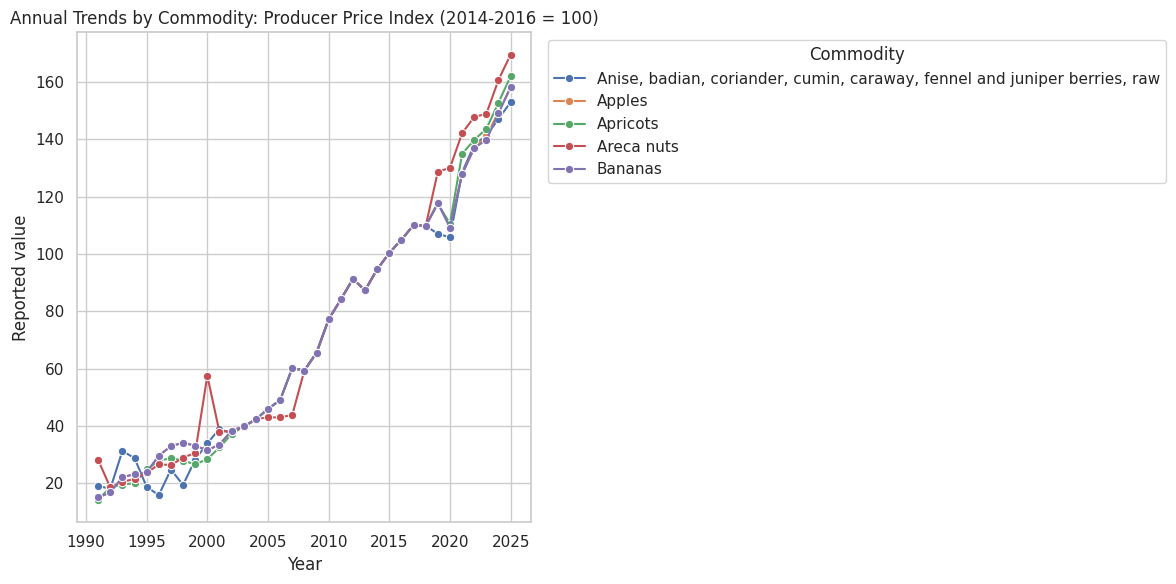


Measurement type: Producer Price Index (2014-2016 = 100)


,item,year,value,observations
0,"Anise, badian, coriander, cumin, caraway, fenn...",1991,19.06,1
1,"Anise, badian, coriander, cumin, caraway, fenn...",1992,17.96,1
2,"Anise, badian, coriander, cumin, caraway, fenn...",1993,31.23,1
3,"Anise, badian, coriander, cumin, caraway, fenn...",1994,28.72,1
4,"Anise, badian, coriander, cumin, caraway, fenn...",1995,18.70,1
5,"Anise, badian, coriander, cumin, caraway, fenn...",1996,15.79,1
6,"Anise, badian, coriander, cumin, caraway, fenn...",1997,24.74,1
7,"Anise, badian, coriander, cumin, caraway, fenn...",1998,19.36,1
8,"Anise, badian, coriander, cumin, caraway, fenn...",1999,28.15,1
9,"Anise, badian, coriander, cumin, caraway, fenn...",2000,33.90,1


In [9]:
# STEP 9: Improved time-series trend analysis

for element in analysis_data["element"].dropna().unique():

    subset = analysis_data[
        analysis_data["element"] == element
    ].dropna(subset=["year", "value", "item"]).copy()

    if subset.empty:
        continue

    # Select the five commodities with the most observations
    top_items = subset["item"].value_counts().head(5).index

    plot_data = subset[subset["item"].isin(top_items)].copy()

    # Aggregate duplicate records for the same commodity and year.
    # This is an arithmetic mean within the same measurement type.
    trend_data = (
        plot_data.groupby(["item", "year"], as_index=False)
        .agg(
            value=("value", "mean"),
            observations=("value", "size")
        )
        .sort_values(["item", "year"])
    )

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=trend_data,
        x="year",
        y="value",
        hue="item",
        marker="o",
        estimator=None
    )

    plt.title(f"Annual Trends by Commodity: {element}")
    plt.xlabel("Year")
    plt.ylabel("Reported value")
    plt.legend(
        title="Commodity",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    plt.tight_layout()
    save_and_show()

    print(f"\nMeasurement type: {element}")
    display(trend_data.head(10))


Measurement type: Producer Price (LCU/tonne)
Common comparison years: 1991-2008
Number of common years: 17
Chart saved: 010_Commodity_Comparison_Producer_Price_LCU_tonne_Common_years_1991-2008.png


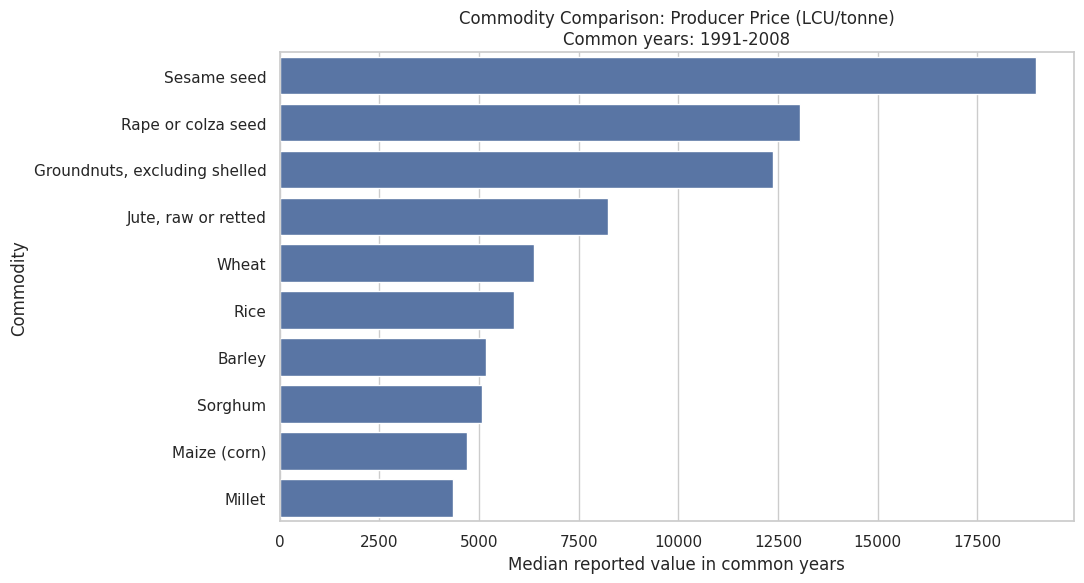

,item,Median_Value
0,Sesame seed,18977.9
1,Rape or colza seed,13059.0
2,"Groundnuts, excluding shelled",12380.0
3,"Jute, raw or retted",8246.0
4,Wheat,6373.0
5,Rice,5877.3
6,Barley,5175.0
7,Sorghum,5090.0
8,Maize (corn),4712.0
9,Millet,4347.0



Measurement type: Producer Price (SLC/tonne)
Common comparison years: 1991-2008
Number of common years: 17
Chart saved: 011_Commodity_Comparison_Producer_Price_SLC_tonne_Common_years_1991-2008.png


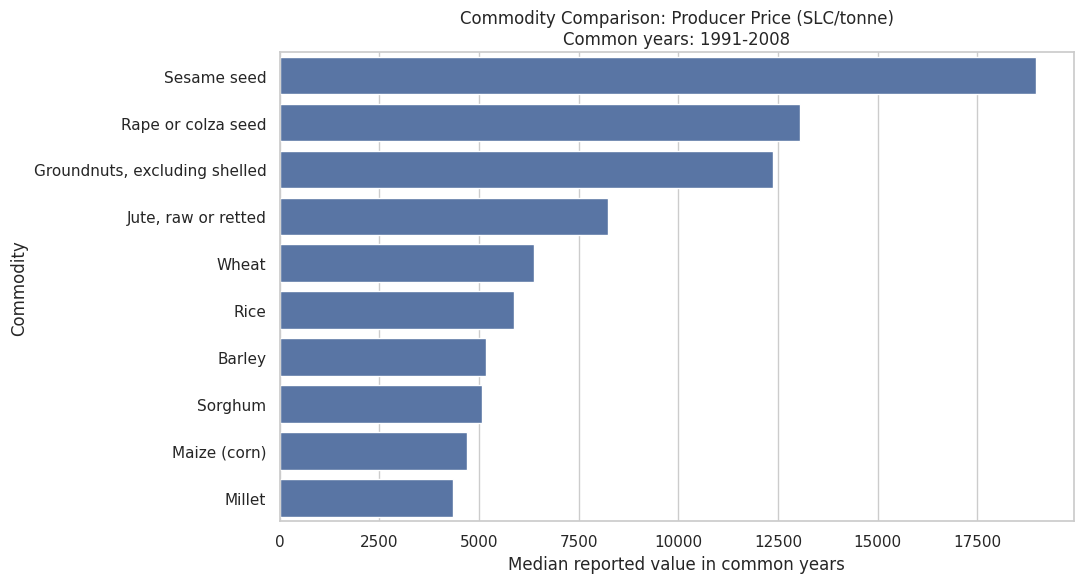

,item,Median_Value
0,Sesame seed,18977.9
1,Rape or colza seed,13059.0
2,"Groundnuts, excluding shelled",12380.0
3,"Jute, raw or retted",8246.0
4,Wheat,6373.0
5,Rice,5877.3
6,Barley,5175.0
7,Sorghum,5090.0
8,Maize (corn),4712.0
9,Millet,4347.0



Measurement type: Producer Price (USD/tonne)
Common comparison years: 1991-2008
Number of common years: 17
Chart saved: 012_Commodity_Comparison_Producer_Price_USD_tonne_Common_years_1991-2008.png


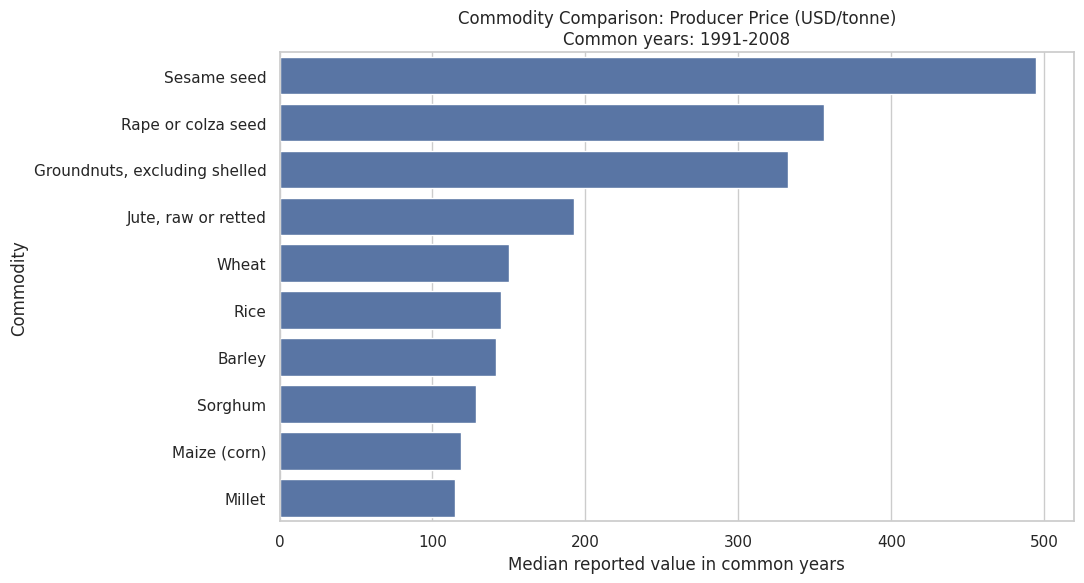

,item,Median_Value
0,Sesame seed,494.8
1,Rape or colza seed,356.1
2,"Groundnuts, excluding shelled",332.5
3,"Jute, raw or retted",192.4
4,Wheat,149.8
5,Rice,144.6
6,Barley,141.3
7,Sorghum,128.2
8,Maize (corn),118.4
9,Millet,114.7



Measurement type: Producer Price Index (2014-2016 = 100)
Common comparison years: 1991-2025
Number of common years: 35
Chart saved: 013_Commodity_Comparison_Producer_Price_Index_2014-2016_100_Common_years_1991-2025.png


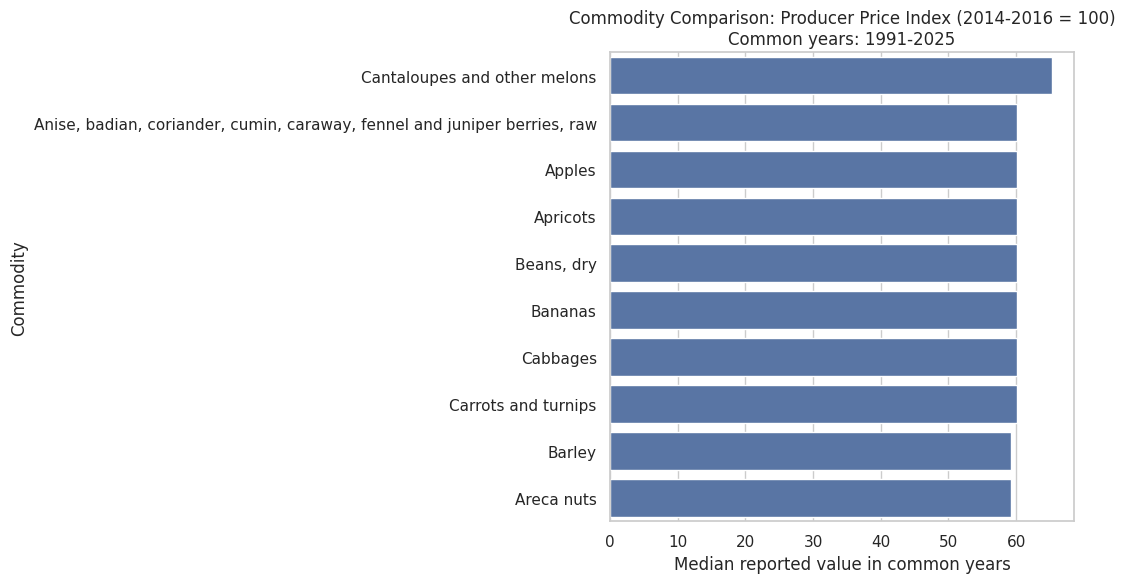

,item,Median_Value
0,Cantaloupes and other melons,65.29
1,"Anise, badian, coriander, cumin, caraway, fenn...",60.15
2,Apples,60.15
3,Apricots,60.15
4,"Beans, dry",60.15
5,Bananas,60.15
6,Cabbages,60.15
7,Carrots and turnips,60.15
8,Barley,59.31
9,Areca nuts,59.31


In [10]:
# STEP 10: Fair commodity comparison using common years

for element in analysis_data["element"].dropna().unique():

    subset = analysis_data[
        analysis_data["element"] == element
    ].dropna(subset=["item", "year", "value"]).copy()

    if subset.empty:
        continue

    # Select the 10 most frequently observed commodities
    top_items = subset["item"].value_counts().head(10).index

    plot_data = subset[
        subset["item"].isin(top_items)
    ].copy()

    # One value per commodity-year, averaging duplicate records
    annual_values = (
        plot_data.groupby(["item", "year"])["value"]
        .mean()
        .unstack("item")
    )

    # Keep only years with an observation for every selected commodity
    common_years = annual_values.dropna(axis=0, how="any")

    if common_years.empty:
        print(
            f"No common years for all selected commodities "
            f"under {element}. Skipping comparison."
        )
        continue

    # Report the actual comparison period
    first_year = int(common_years.index.min())
    last_year = int(common_years.index.max())

    # Calculate each commodity's median within the common period
    comparison = common_years.median().sort_values(
        ascending=False
    )

    print(f"\nMeasurement type: {element}")
    print(f"Common comparison years: {first_year}-{last_year}")
    print(f"Number of common years: {len(common_years)}")

    plt.figure(figsize=(11, 6))

    sns.barplot(
        x=comparison.values,
        y=comparison.index
    )

    plt.title(
        f"Commodity Comparison: {element}\n"
        f"Common years: {first_year}-{last_year}"
    )
    plt.xlabel("Median reported value in common years")
    plt.ylabel("Commodity")
    plt.tight_layout()
    save_and_show()

    display(
        comparison.rename("Median_Value").reset_index()
    )

In [11]:
# STEP 11: Potential outlier detection using the IQR method
# Outliers are flagged, not automatically removed.

def detect_outliers(group):
    values = group["value"].dropna()

    if len(values) < 4:
        return pd.DataFrame()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    result = group[
        (group["value"] < lower_bound) |
        (group["value"] > upper_bound)
    ].copy()

    result["Lower_Bound"] = lower_bound
    result["Upper_Bound"] = upper_bound
    return result

outlier_groups = []

for _, group in analysis_data.groupby(["element", "item"], dropna=False):
    detected = detect_outliers(group)
    if not detected.empty:
        outlier_groups.append(detected)

if outlier_groups:
    outliers = pd.concat(outlier_groups, ignore_index=True)
    print("Potential outlier records:", len(outliers))
    display(outliers.head(50))
else:
    outliers = pd.DataFrame()
    print("No outliers identified by the selected IQR rule.")

print("Investigate unusual observations before considering any exclusion.")

Potential outlier records: 62


,domain_code,domain,area_code_m49,area,element_code,element,item_code_cpc,item,year_code,year,months_code,months,unit,value,flag,flag_description,Lower_Bound,Upper_Bound
0,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0115,Barley,2005,2005,7021,Annual value,LCU,7684.0,A,Official value,3332.0000,7380.0000
1,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0115,Barley,2006,2006,7021,Annual value,LCU,8193.3,A,Official value,3332.0000,7380.0000
2,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0115,Barley,2008,2008,7021,Annual value,LCU,9855.8,A,Official value,3332.0000,7380.0000
3,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0142,"Groundnuts, excluding shelled",2008,2008,7021,Annual value,LCU,21000.0,A,Official value,6243.7500,19853.7500
4,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),01922.01,"Jute, raw or retted",2008,2008,7021,Annual value,LCU,12500.0,A,Official value,2745.5000,12301.5000
5,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),01704,"Lentils, dry",1991,1991,7021,Annual value,LCU,6737.0,X,Value from external organization,9741.8750,18754.8750
6,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0112,Maize (corn),2006,2006,7021,Annual value,LCU,7667.1,A,Official value,2052.5000,6960.5000
7,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0112,Maize (corn),2008,2008,7021,Annual value,LCU,8400.0,A,Official value,2052.5000,6960.5000
8,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0118,Millet,2008,2008,7021,Annual value,LCU,8400.0,A,Official value,964.0000,8004.0000
9,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0113,Rice,2004,2004,7021,Annual value,LCU,9410.0,A,Official value,1647.1500,9014.7500


Investigate unusual observations before considering any exclusion.


,Measurement,Commodity,Years_Observed,First_Year,Last_Year,Year_Value_Correlation
9,Producer Price (LCU/tonne),"Lentils, dry",4,1991,2006,0.995
19,Producer Price (LCU/tonne),Raw milk of cattle,4,1991,1994,0.993
10,Producer Price (LCU/tonne),Linseed,16,1991,2006,0.975
2,Producer Price (LCU/tonne),"Chick peas, dry",16,1991,2006,0.966
29,Producer Price (LCU/tonne),Wheat,18,1991,2008,0.963
...,...,...,...,...,...,...
186,Producer Price Index (2014-2016 = 100),Sunflower seed,35,1991,2025,0.947
118,Producer Price Index (2014-2016 = 100),Green garlic,35,1991,2025,0.946
98,Producer Price Index (2014-2016 = 100),Cantaloupes and other melons,35,1991,2025,0.941
109,Producer Price Index (2014-2016 = 100),"Coconuts, in shell",35,1991,2025,0.919


Chart saved: 014_Commodity-Level_Year_Value_Correlation_Producer_Price_LCU_tonne.png


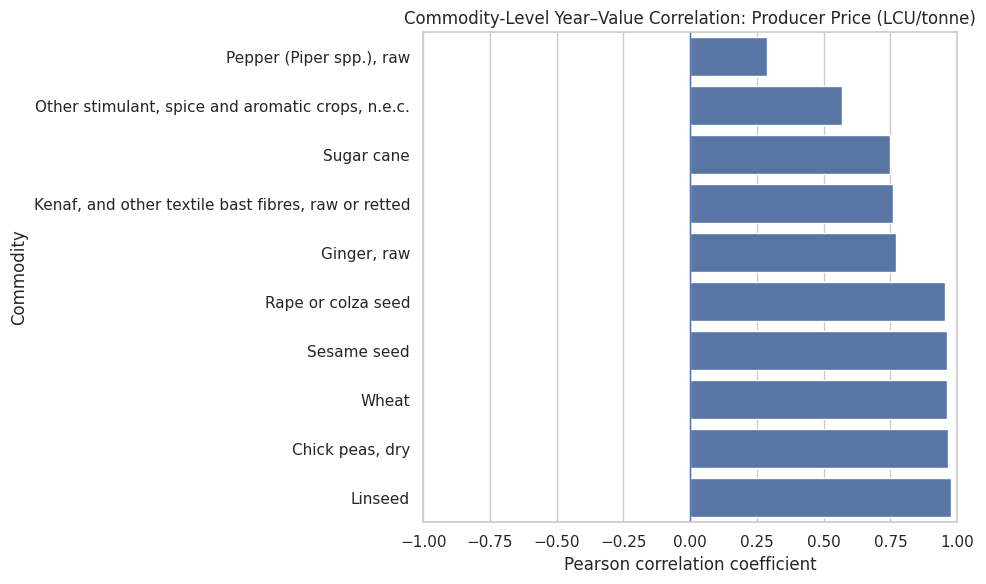

Chart saved: 015_Commodity-Level_Year_Value_Correlation_Producer_Price_SLC_tonne.png


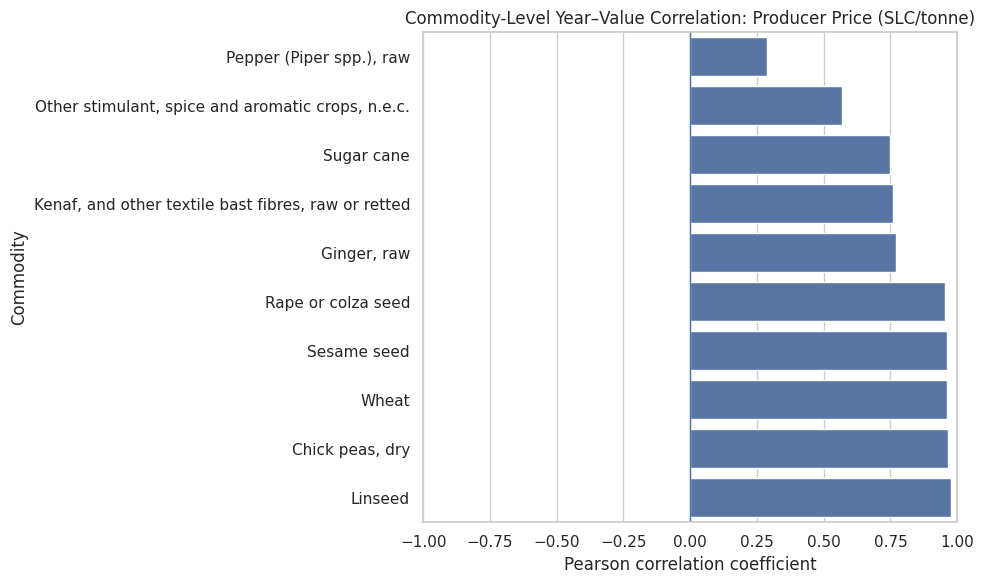

Chart saved: 016_Commodity-Level_Year_Value_Correlation_Producer_Price_USD_tonne.png


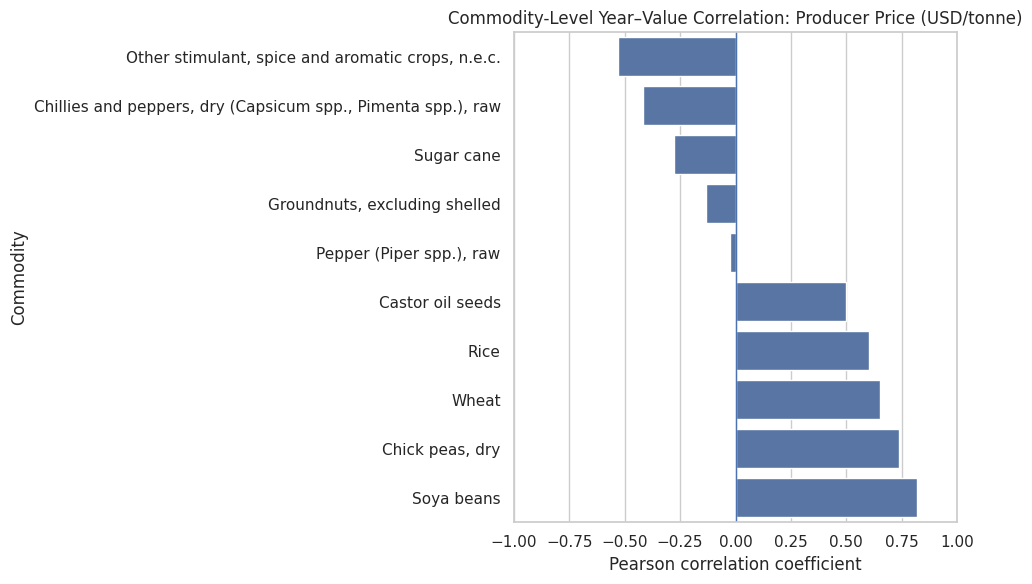

Chart saved: 017_Commodity-Level_Year_Value_Correlation_Producer_Price_Index_2014-2016_100.png


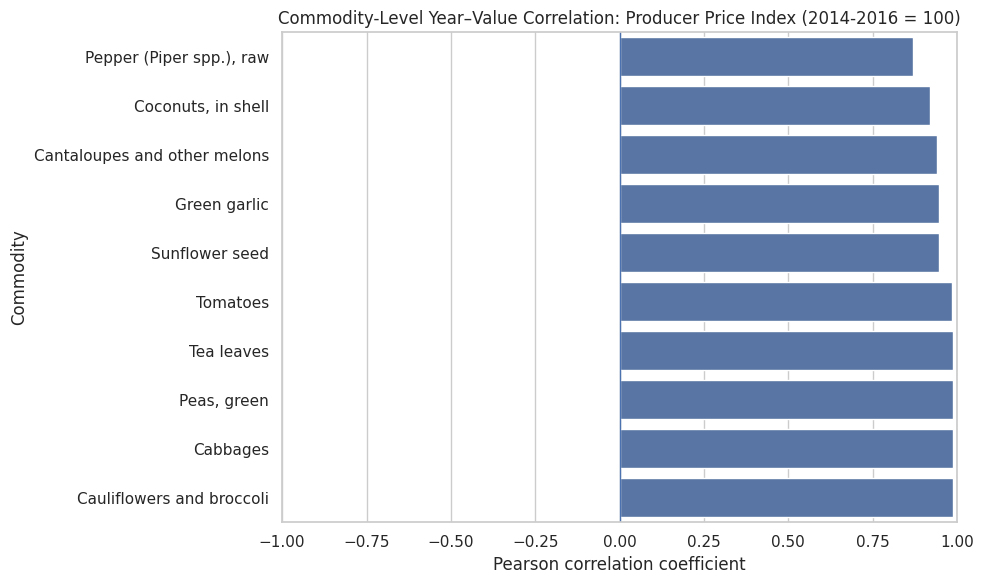

Saved detailed results to /content/correlation_by_commodity.csv


In [12]:
# STEP 12: Correlation by individual commodity and measurement type

correlation_results = []

for (element, item), group in analysis_data.groupby(
    ["element", "item"], dropna=False
):

    group = group.dropna(subset=["year", "value"]).copy()

    # Average duplicate records for the same commodity and year
    series = (
        group.groupby("year")["value"]
        .mean()
        .sort_index()
    )

    # Require at least 3 distinct years
    if len(series) < 3:
        continue

    # Pearson correlation between year and annual value
    correlation = series.index.to_series().corr(
        series,
        method="pearson"
    )

    correlation_results.append({
        "Measurement": element,
        "Commodity": item,
        "Years_Observed": len(series),
        "First_Year": int(series.index.min()),
        "Last_Year": int(series.index.max()),
        "Year_Value_Correlation": correlation
    })

correlation_by_commodity = pd.DataFrame(correlation_results)

if not correlation_by_commodity.empty:

    correlation_by_commodity = correlation_by_commodity.sort_values(
        ["Measurement", "Year_Value_Correlation"],
        ascending=[True, False]
    )

    display(correlation_by_commodity.round(3))

    # Plot the strongest positive and negative correlations
    # only for series with at least 10 distinct years.
    reliable_coverage = correlation_by_commodity[
        correlation_by_commodity["Years_Observed"] >= 10
    ].copy()

    if not reliable_coverage.empty:

        for element in reliable_coverage["Measurement"].unique():

            subset = reliable_coverage[
                reliable_coverage["Measurement"] == element
            ]

            strongest_positive = subset.nlargest(
                5, "Year_Value_Correlation"
            )

            strongest_negative = subset.nsmallest(
                5, "Year_Value_Correlation"
            )

            selected = pd.concat([
                strongest_positive,
                strongest_negative
            ]).drop_duplicates(
                subset=["Commodity"]
            )

            selected = selected.sort_values(
                "Year_Value_Correlation"
            )

            plt.figure(figsize=(10, 6))

            sns.barplot(
                data=selected,
                x="Year_Value_Correlation",
                y="Commodity"
            )

            plt.axvline(0, linewidth=1)
            plt.xlim(-1, 1)
            plt.title(
                f"Commodity-Level Year–Value Correlation: {element}"
            )
            plt.xlabel("Pearson correlation coefficient")
            plt.ylabel("Commodity")
            plt.tight_layout()
            save_and_show()

    else:
        print(
            "No commodity series has at least 10 distinct years. "
            "Review the coverage before interpreting correlations."
        )

else:
    print("Not enough annual observations to calculate correlations.")

# Save results for the Week 3 report
correlation_by_commodity.to_csv(
    "/content/correlation_by_commodity.csv",
    index=False
)

print(
    "Saved detailed results to "
    "/content/correlation_by_commodity.csv"
)

,year,value
4946,1991,3855.0
4947,1992,3899.0
4948,1993,4091.0
4949,1994,4250.0
4950,1995,4713.0
4951,1996,5790.0
4952,1997,5518.0
4953,1998,5945.0
4954,1999,6373.0
4955,2000,6649.0


Chart saved: 018_Wheat_Producer_Price_in_India_LCU_tonne.png


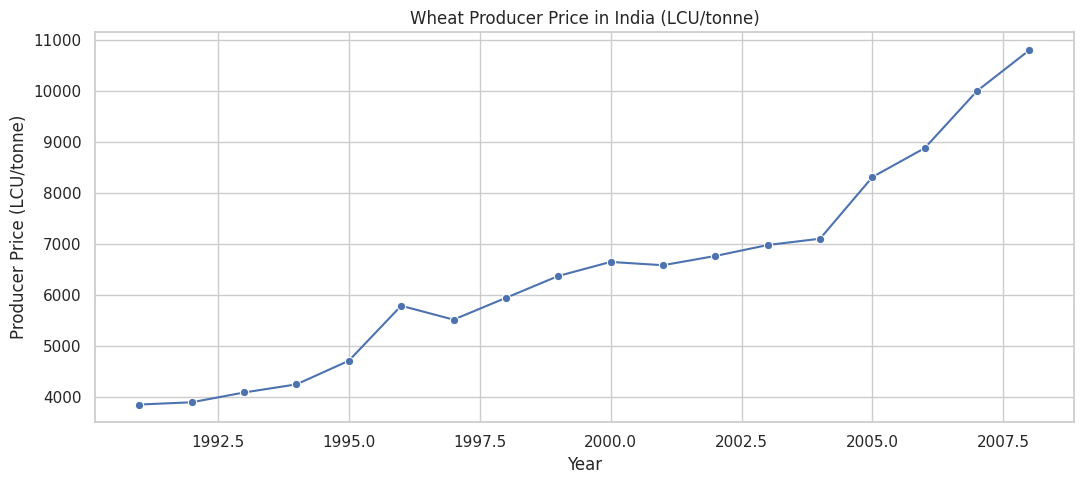

First observed year: 1991
Last observed year: 2008
Lowest reported value: 3855.0
Highest reported value: 10800.0


In [13]:
# STEP 13: Wheat producer-price case study

wheat_lcu = analysis_data[
    (analysis_data["item"].astype(str).str.lower() == "wheat") &
    (analysis_data["element"] == "Producer Price (LCU/tonne)")
].dropna(subset=["year", "value"]).sort_values("year").copy()

if not wheat_lcu.empty:
    display(wheat_lcu[["year", "value"]])

    plt.figure(figsize=(11, 5))
    sns.lineplot(data=wheat_lcu, x="year", y="value", marker="o")
    plt.title("Wheat Producer Price in India (LCU/tonne)")
    plt.xlabel("Year")
    plt.ylabel("Producer Price (LCU/tonne)")
    plt.tight_layout()
    save_and_show()

    print("First observed year:", wheat_lcu["year"].min())
    print("Last observed year:", wheat_lcu["year"].max())
    print("Lowest reported value:", wheat_lcu["value"].min())
    print("Highest reported value:", wheat_lcu["value"].max())
else:
    print("No wheat LCU/tonne observations are available.")

In [14]:
# STEP 14: Summary tables for the report

commodity_summary = analysis_data.groupby(
    ["element", "item"], dropna=False
).agg(
    Observation_Count=("value", "count"),
    First_Year=("year", "min"),
    Last_Year=("year", "max"),
    Mean_Value=("value", "mean"),
    Median_Value=("value", "median"),
    Minimum_Value=("value", "min"),
    Maximum_Value=("value", "max")
).reset_index()

annual_summary = analysis_data.groupby(
    ["element", "year"], dropna=False
).agg(
    Observation_Count=("value", "count"),
    Mean_Value=("value", "mean"),
    Median_Value=("value", "median")
).reset_index()

display(Markdown("### Commodity summary"))
display(commodity_summary.head(20))
display(Markdown("### Annual summary"))
display(annual_summary.head(20))

### Commodity summary

,element,item,Observation_Count,First_Year,Last_Year,Mean_Value,Median_Value,Minimum_Value,Maximum_Value
0,Producer Price (LCU/tonne),"Anise, badian, coriander, cumin, caraway, fenn...",1,2001,2001,29485.000000,29485.0,29485.0,29485.0
1,Producer Price (LCU/tonne),Apples,1,2001,2001,21327.000000,21327.0,21327.0,21327.0
2,Producer Price (LCU/tonne),Areca nuts,2,1991,2001,50082.500000,50082.5,42695.0,57470.0
3,Producer Price (LCU/tonne),Bananas,1,2001,2001,5980.000000,5980.0,5980.0,5980.0
4,Producer Price (LCU/tonne),Barley,17,1991,2008,5627.141176,5175.0,3489.0,9855.8
5,Producer Price (LCU/tonne),"Beans, dry",1,1991,1991,5982.000000,5982.0,5982.0,5982.0
6,Producer Price (LCU/tonne),Cabbages,1,2001,2001,5550.000000,5550.0,5550.0,5550.0
7,Producer Price (LCU/tonne),"Cashew nuts, in shell",2,1991,2001,23525.500000,23525.5,14521.0,32530.0
8,Producer Price (LCU/tonne),Castor oil seeds,16,1991,2006,11818.450000,11374.0,6544.0,16884.3
9,Producer Price (LCU/tonne),Cauliflowers and broccoli,1,2001,2001,11211.000000,11211.0,11211.0,11211.0


### Annual summary

,element,year,Observation_Count,Mean_Value,Median_Value
0,Producer Price (LCU/tonne),1991,45,14832.800000,7530.00
1,Producer Price (LCU/tonne),1992,26,9211.923077,8583.50
2,Producer Price (LCU/tonne),1993,25,10154.720000,9736.00
3,Producer Price (LCU/tonne),1994,26,12263.115385,11022.00
4,Producer Price (LCU/tonne),1995,24,13969.291667,11700.50
5,Producer Price (LCU/tonne),1996,22,11829.590909,10220.00
6,Producer Price (LCU/tonne),1997,23,15724.565217,12550.00
7,Producer Price (LCU/tonne),1998,24,18478.125000,12987.00
8,Producer Price (LCU/tonne),1999,24,18842.791667,12463.00
9,Producer Price (LCU/tonne),2000,24,17979.833333,12535.00


## Week 3 EDA Report Outline

1. **Executive Summary:** Summarize the main patterns supported by the analysis.
2. **Introduction and Objectives:** Explain the value of price analysis for agribusiness.
3. **Dataset Description:** State source, geographic coverage, years, commodities, variables, and units.
4. **Methodology:** Describe data preparation, descriptive statistics, trend analysis, and visualizations.
5. **Data Quality Assessment:** Report missing values, duplicates, data types, and measurement consistency.
6. **Univariate Analysis:** Interpret histograms and descriptive statistics.
7. **Time-Series Analysis:** Discuss price movements over time and data gaps.
8. **Commodity and Regional Analysis:** Compare available commodities and regions using comparable measures.
9. **Outlier and Correlation Analysis:** Explain the IQR method and correlation limitations.
10. **Key Findings and Business Implications:** Connect observed patterns to potential agribusiness decisions.
11. **Recommendations:** Suggest further checks and additional data needed.
12. **Limitations and Conclusion:** State the limits of annual data and summarize evidence.
13. **References and Appendix:** Cite FAOSTAT, pandas, Matplotlib, and Seaborn.

**Limitations to acknowledge:** The dataset is annual, so seasonal patterns cannot be assessed. Price changes alone do not establish causes such as weather, policy, or production costs. Use monthly market data and production/weather variables for those questions.

In [15]:
# STEP 15: Save output tables and report outline

os.makedirs(output_dir, exist_ok=True)
os.makedirs(chart_dir, exist_ok=True)

missing_summary.to_csv(
    f"{output_dir}/missing_value_summary.csv", index=True
)
descriptive_stats.to_csv(
    f"{output_dir}/descriptive_statistics.csv", index=False
)
commodity_summary.to_csv(
    f"{output_dir}/commodity_summary.csv", index=False
)
annual_summary.to_csv(
    f"{output_dir}/annual_summary.csv", index=False
)
correlation_by_commodity.to_csv(
    f"{output_dir}/correlation_by_commodity.csv", index=False
)

# Save a compact correlation summary for easier reporting.
if not correlation_by_commodity.empty:
    correlation_summary = (
        correlation_by_commodity.groupby("Measurement", dropna=False)
        .agg(
            Commodity_Count=("Commodity", "nunique"),
            Mean_Correlation=("Year_Value_Correlation", "mean"),
            Median_Correlation=("Year_Value_Correlation", "median")
        )
        .reset_index()
    )
else:
    correlation_summary = pd.DataFrame(
        columns=[
            "Measurement", "Commodity_Count",
            "Mean_Correlation", "Median_Correlation"
        ]
    )

correlation_summary.to_csv(
    f"{output_dir}/correlation_summary.csv", index=False
)

if not outliers.empty:
    outliers.to_csv(
        f"{output_dir}/potential_outliers.csv", index=False
    )

report_outline = """# Exploratory Data Analysis Report: Agribusiness Trends

## 1. Executive Summary
## 2. Introduction and Objectives
## 3. Dataset Description
## 4. Methodology
## 5. Data Quality Assessment
## 6. Univariate Analysis
## 7. Time-Series Analysis
## 8. Commodity and Regional Analysis
## 9. Outlier and Correlation Analysis
## 10. Key Findings and Business Implications
## 11. Recommendations
## 12. Limitations and Conclusion
## 13. References and Appendix
"""

with open(
    f"{output_dir}/EDA_Report_Outline.md", "w", encoding="utf-8"
) as file:
    file.write(report_outline)

# Create a manifest of all generated outputs.
output_files = []
for root, _, filenames in os.walk(output_dir):
    for filename in filenames:
        full_path = os.path.join(root, filename)
        output_files.append(os.path.relpath(full_path, output_dir))

manifest_path = os.path.join(output_dir, "output_manifest.txt")
with open(manifest_path, "w", encoding="utf-8") as manifest:
    manifest.write("\\n".join(sorted(output_files)))

zip_path = shutil.make_archive(
    "/content/Week3_EDA_Outputs", "zip", output_dir
)

print("EDA analysis completed.")
print("Charts saved:", len([
    name for name in os.listdir(chart_dir)
    if name.lower().endswith(".png")
]))
print("Output folder:", output_dir)
print("ZIP archive:", zip_path)

# In Google Colab, download the results archive:
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Google Colab. Download the ZIP from the output path above.")

EDA analysis completed.
Charts saved: 18
Output folder: /content/Week3_EDA_Outputs
ZIP archive: /content/Week3_EDA_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>